# Exploratory C: M2 and GARCH on the Bundesbank German curve

*Exploratory notebook, not part of the roadmap.*

**Question.** The euro AAA history covers only 22 years (2004-2026), so the M4 and M4.5 validations rest on 7-11 independent years. Do the findings (horizon miscalibration, short-end trending, no gain from GARCH) hold on a longer history?

**Data.** Bundesbank Svensson zero-coupon curve for German federal securities (`load_curve("DE")`): daily values for all six maturities from 2000-08-01 to 2026-11-20 (6,684 days). The daily series starts in 1997 (30Y in 2000); earlier years only have month-end values. Design B uses origins 2006-2022 (17 test years instead of 11). The analysis is otherwise the same as `06_garch.ipynb`.

In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox
from scenario_lab.data import load_curve
from scenario_lab.models import var1 as m, var1_garch as gm
from scenario_lab.models.sigma_garch import Garch11
from scenario_lab import validation as v
plt.style.use("default"); plt.rcParams["figure.facecolor"] = "white"

levels = load_curve("DE")
changes = levels.diff().dropna()
realised = v.realised_changes(levels)
FIT_END = v.FIT_END
mats = list(levels.columns)
print("fit end:", FIT_END, "| daily changes:", changes.shape)

fit end: 2018-12-31 | daily changes: (6683, 6)


## 1. GARCH layer: parameters and diagnostics (full sample)

Fitted parameters per factor, the conditional volatility path against M2's constant sigma, and residual checks: a QQ plot of `z = eps / sigma_t` against the fitted t, and the autocorrelation of squares before and after standardising (Ljung-Box at lag 10).

In [2]:
pg = gm.fit(changes)
pb = m.fit(changes)                                   # constant-volatility baseline

tab = pd.DataFrame([g.params._asdict() for g in pg.garch], index=["PC1", "PC2", "PC3"])
tab["alpha+beta"] = tab.alpha + tab.beta
tab["long-run std"] = np.sqrt(tab.omega / (1 - tab["alpha+beta"]))
tab["sigma now"] = np.sqrt([g.sigma2_last for g in pg.garch])
tab["M2 constant sigma"] = pb.sigma
print(tab.round(4))

     omega   alpha    beta      nu  alpha+beta  long-run std  sigma now  \
PC1    0.0  0.0468  0.9490  7.7068      0.9958        0.1050     0.0871   
PC2    0.0  0.0625  0.9367  5.3649      0.9991        0.0995     0.0332   
PC3    0.0  0.0999  0.9001  5.1624      1.0000           inf     0.0092   

     M2 constant sigma  
PC1             0.0969  
PC2             0.0455  
PC3             0.0237  


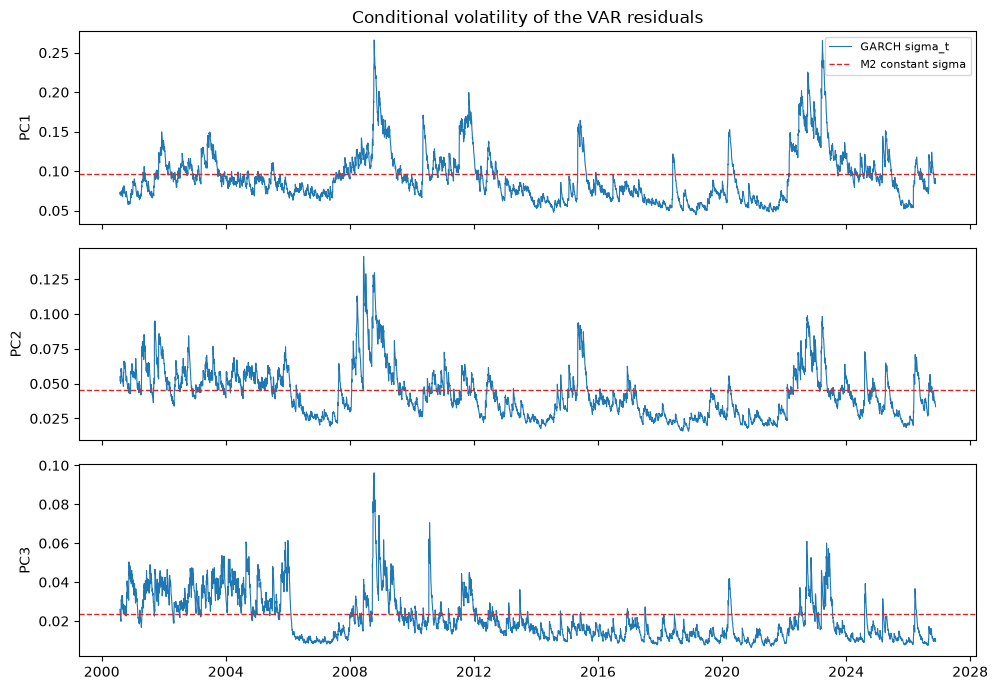

In [3]:
scores = changes.values @ pg.V
resid = scores[1:] - scores[:-1] @ pg.Phi.T          # VAR residuals (T-1, 3)
dates = changes.index[1:]
sig = np.column_stack([
    np.sqrt(Garch11.variance(resid[:, j], *pg.garch[j].params[:3], Garch11.backcast(resid[:, j]))[:-1])
    for j in range(3)])                              # sigma_t per factor, original scale
z = resid / sig

fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for j, ax in enumerate(axes):
    ax.plot(dates, sig[:, j], lw=0.8, label="GARCH sigma_t")
    ax.axhline(pb.sigma[j], color="C3", ls="--", lw=1, label="M2 constant sigma")
    ax.set_ylabel(f"PC{j+1}")
axes[0].legend(fontsize=8); axes[0].set_title("Conditional volatility of the VAR residuals")
plt.tight_layout(); plt.show()

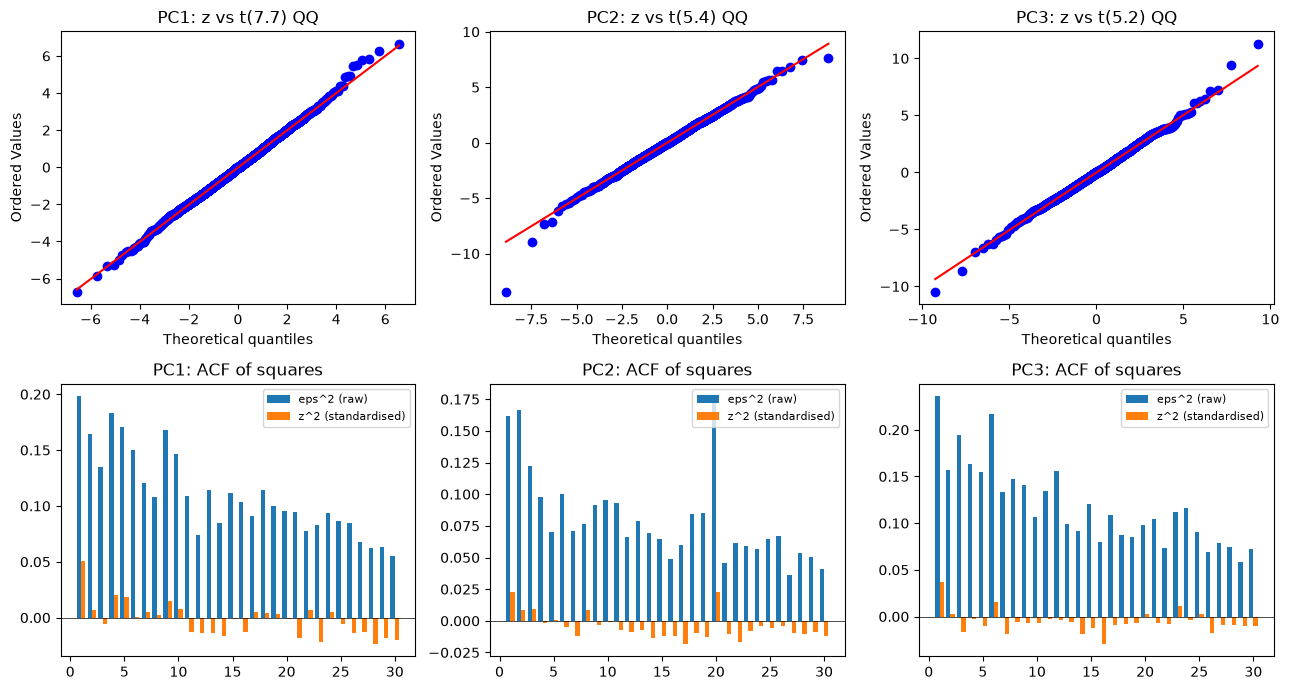

Ljung-Box p-value on squares, lag 10 (small = volatility clustering left)
     raw eps^2  standardised z^2
PC1        0.0            0.0051
PC2        0.0            0.7902
PC3        0.0            0.0839


In [4]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
lags = np.arange(1, 31)
acf = lambda s: np.array([np.corrcoef(s[:-k], s[k:])[0, 1] for k in lags])
for j in range(3):
    nu = pg.garch[j].params.nu
    stats.probplot(z[:, j] * np.sqrt(nu / (nu - 2)), dist=stats.t, sparams=(nu,), plot=axes[0, j])
    axes[0, j].set_title(f"PC{j+1}: z vs t({nu:.1f}) QQ")
    ax = axes[1, j]
    ax.bar(lags - 0.2, acf(resid[:, j] ** 2), 0.4, label="eps^2 (raw)")
    ax.bar(lags + 0.2, acf(z[:, j] ** 2), 0.4, label="z^2 (standardised)")
    ax.axhline(0, color="k", lw=0.5); ax.set_title(f"PC{j+1}: ACF of squares"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

lb = pd.DataFrame({"raw eps^2": [acorr_ljungbox(resid[:, j] ** 2, lags=[10])["lb_pvalue"].iloc[0] for j in range(3)],
                   "standardised z^2": [acorr_ljungbox(z[:, j] ** 2, lags=[10])["lb_pvalue"].iloc[0] for j in range(3)]},
                  index=["PC1", "PC2", "PC3"])
print("Ljung-Box p-value on squares, lag 10 (small = volatility clustering left)")
print(lb.round(4))

## 2. Simulation from today's curve

250-day simulations from the last curve with both models. Left: daily std of the simulated changes by simulation day (GARCH starts from the current volatility and reverts towards its long-run level). Right: std of the 250-day change by maturity.

garch (25000, 251, 6) finite: True


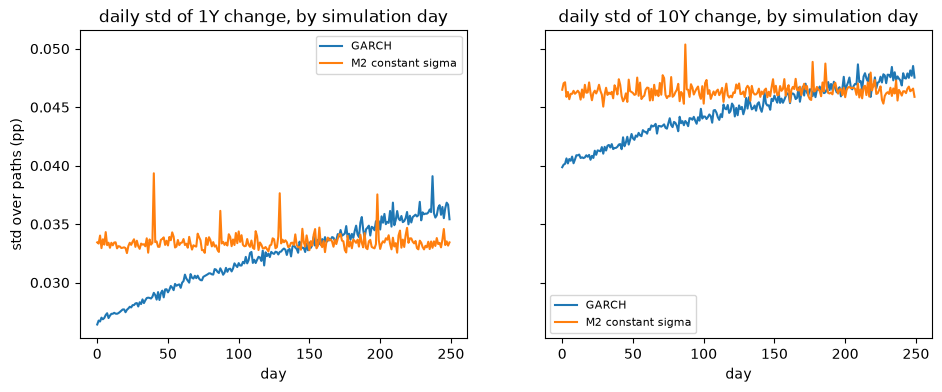

std of the 250-day change (pp)
     GARCH     M2  realised 250d (all)
1Y   0.503  0.518                1.041
2Y   0.647  0.664                0.945
5Y   0.687  0.710                0.782
10Y  0.679  0.706                0.709
20Y  0.693  0.718                0.706
30Y  0.751  0.783                0.689


In [5]:
y0 = levels.iloc[-1].values
cg = gm.simulate(pg, y0, seed=0)
cb = m.simulate(pb, y0, seed=0)
print("garch", cg.shape, "finite:", np.isfinite(cg).all())

dstd_g = np.diff(cg, axis=1).std(axis=0)             # (250, 6) daily std over paths, by day
dstd_b = np.diff(cb, axis=1).std(axis=0)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, k in zip(axes, [0, 3]):
    ax.plot(dstd_g[:, k], label="GARCH"); ax.plot(dstd_b[:, k], label="M2 constant sigma")
    ax.set_title(f"daily std of {mats[k]} change, by simulation day"); ax.set_xlabel("day"); ax.legend(fontsize=8)
axes[0].set_ylabel("std over paths (pp)")
plt.show()

out = pd.DataFrame({"GARCH": (cg[:, -1] - y0).std(0), "M2": (cb[:, -1] - y0).std(0),
                    "realised 250d (all)": realised.std().values}, index=mats)
print("std of the 250-day change (pp)")
print(out.round(3))

### Variance ratio of the 250-day change

`VR = var(250-day change) / (250 * var(daily change))`. VR = 1 when daily changes are uncorrelated, above 1 when the spread accumulates faster (trending). Realised values use all overlapping 250-day windows; simulated values use the paths above. A gap between realised and simulated VR cannot be closed by a better daily volatility.

In [6]:
vr_real = realised.var() / (250 * changes.var())
vr_m2 = pd.Series((cb[:, -1] - y0).var(0) / (250 * np.diff(cb, axis=1).reshape(-1, 6).var(0)), index=mats)
vr_g = pd.Series((cg[:, -1] - y0).var(0) / (250 * np.diff(cg, axis=1).reshape(-1, 6).var(0)), index=mats)
print(pd.DataFrame({"realised": vr_real, "M2": vr_m2, "GARCH": vr_g}).round(2))

     realised    M2  GARCH
1Y       3.53  0.96   0.97
2Y       1.90  0.96   0.97
5Y       1.09  0.94   0.94
10Y      0.91  0.93   0.92
20Y      0.89  0.95   0.94
30Y      0.70  0.91   0.90


## Design A: single cut (end-2018)

Fit on data up to the cut, simulate from that curve, compare with the realised 250-day changes starting at or after the cut (as in `05_validation.ipynb`). M2 is re-run so both models are scored on the same windows. Coverage is the fraction of realised changes inside the simulated band (nominal 0.90 for 5-95%, 0.50 for 25-75%).

In [7]:
y0_a = levels.loc[:FIT_END].iloc[-1].values
pa_g = gm.fit(changes.loc[:FIT_END]); pa_b = m.fit(changes.loc[:FIT_END])
cg_a = gm.simulate(pa_g, y0_a, seed=0); cb_a = m.simulate(pa_b, y0_a, seed=0)
sim_g = cg_a[:, -1] - cg_a[:, 0]; sim_b = cb_a[:, -1] - cb_a[:, 0]

test = realised.loc[FIT_END:]
train = realised.loc[:FIT_END].iloc[:-250]
print("test windows:", len(test), "(about", round(len(test) / 250, 1), "independent years)")
for band, (lo, hi), nom in [("5-95%", (0.05, 0.95), 0.9), ("25-75%", (0.25, 0.75), 0.5)]:
    print(f"\ncoverage {band} (nominal {nom:.0%})")
    print(pd.DataFrame({"M2 test": v.coverage(sim_b, test, lo, hi), "GARCH test": v.coverage(sim_g, test, lo, hi),
                        "M2 train": v.coverage(sim_b, train, lo, hi), "GARCH train": v.coverage(sim_g, train, lo, hi)}).round(3))

test windows: 1757 (about 7.0 independent years)

coverage 5-95% (nominal 90%)
     M2 test  GARCH test  M2 train  GARCH train
1Y     0.605       0.525     0.723        0.681
2Y     0.740       0.624     0.812        0.747
5Y     0.802       0.763     0.873        0.802
10Y    0.826       0.800     0.923        0.850
20Y    0.837       0.808     0.925        0.847
30Y    0.879       0.820     0.955        0.888

coverage 25-75% (nominal 50%)
     M2 test  GARCH test  M2 train  GARCH train
1Y     0.419       0.378     0.489        0.388
2Y     0.512       0.469     0.582        0.455
5Y     0.592       0.529     0.540        0.451
10Y    0.566       0.446     0.562        0.459
20Y    0.519       0.411     0.604        0.487
30Y    0.520       0.418     0.633        0.529


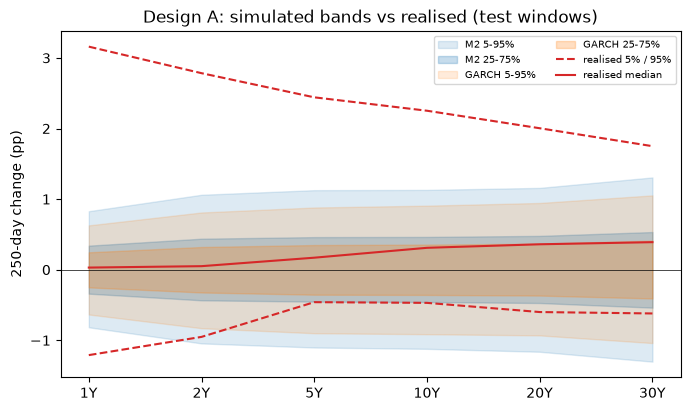

In [8]:
qb, qg = v.horizon_quantiles(cb_a), v.horizon_quantiles(cg_a)
rq = test.quantile([0.05, 0.25, 0.5, 0.75, 0.95])
x = np.arange(len(mats))
fig, ax = plt.subplots(figsize=(8, 4.5))
for q, c, name in [(qb, "C0", "M2"), (qg, "C1", "GARCH")]:
    ax.fill_between(x, q.loc[0.05], q.loc[0.95], alpha=0.15, color=c, label=f"{name} 5-95%")
    ax.fill_between(x, q.loc[0.25], q.loc[0.75], alpha=0.25, color=c, label=f"{name} 25-75%")
ax.plot(x, rq.loc[0.05], "C3--", label="realised 5% / 95%"); ax.plot(x, rq.loc[0.95], "C3--")
ax.plot(x, rq.loc[0.5], "C3-", label="realised median")
ax.axhline(0, color="k", lw=0.5); ax.set_xticks(x); ax.set_xticklabels(mats)
ax.set_ylabel("250-day change (pp)"); ax.set_title("Design A: simulated bands vs realised (test windows)")
ax.legend(fontsize=7, ncol=2); plt.show()

## Design B: expanding window (origins at every year-end 2006-2022)

At each origin both models are fitted on data up to the origin, simulated for 250 days, and scored on the 250 windows starting in the following year. Outputs: pooled and per-origin coverage, and the ratio of simulated to actual daily std in the test year.

In [9]:
origins = [f"{y}-12-31" for y in range(2006, 2023)]
res = {k: {"c90": {}, "c50": {}, "sim_std": {}} for k in ["M2", "GARCH"]}
act_std = {}
for o in origins:
    ch_o, y0_o = changes.loc[:o], levels.loc[:o].iloc[-1].values
    test_o = realised[realised.index > o].iloc[:250]
    act_std[o] = changes[changes.index > o].iloc[:250].std().values
    for name, curves_o in [("M2", m.simulate(m.fit(ch_o), y0_o)), ("GARCH", gm.simulate(gm.fit(ch_o), y0_o))]:
        sim_o = curves_o[:, -1] - curves_o[:, 0]
        res[name]["c90"][o] = v.coverage(sim_o, test_o, 0.05, 0.95)
        res[name]["c50"][o] = v.coverage(sim_o, test_o, 0.25, 0.75)
        res[name]["sim_std"][o] = np.diff(curves_o, axis=1).reshape(-1, 6).std(axis=0)
t90 = {k: pd.DataFrame(v["c90"]).T for k, v in res.items()}
t50 = {k: pd.DataFrame(v["c50"]).T for k, v in res.items()}
print("pooled 5-95% coverage by maturity (nominal 0.90)")
print(pd.DataFrame({k: t.mean() for k, t in t90.items()}).T.round(3))
print("\nmean |coverage - nominal|, all origins and maturities")
print(pd.DataFrame({"5-95%": {k: (t90[k] - 0.9).abs().values.mean() for k in t90},
                    "25-75%": {k: (t50[k] - 0.5).abs().values.mean() for k in t50}}).round(3))

pooled 5-95% coverage by maturity (nominal 0.90)
          1Y    2Y     5Y    10Y    20Y    30Y
M2     0.787  0.82  0.837  0.862  0.848  0.902
GARCH  0.799  0.81  0.835  0.838  0.833  0.877

mean |coverage - nominal|, all origins and maturities
       5-95%  25-75%
M2     0.185   0.311
GARCH  0.193   0.300


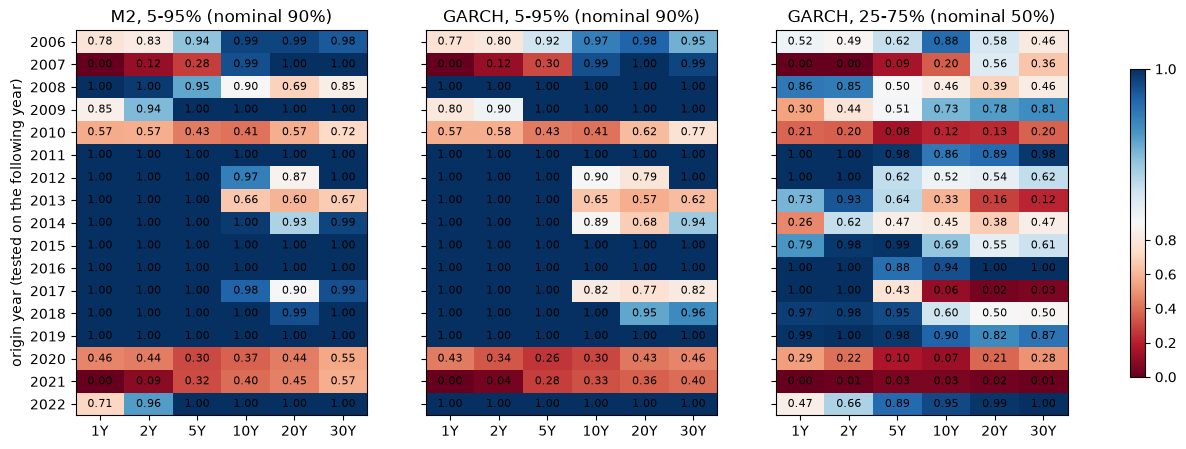

In [10]:
def heat(ax, tab, nominal, title):
    im = ax.imshow(tab.values, cmap="RdBu", norm=TwoSlopeNorm(vcenter=nominal, vmin=0, vmax=1), aspect="auto")
    ax.set_xticks(range(tab.shape[1])); ax.set_xticklabels(tab.columns)
    ax.set_yticks(range(tab.shape[0])); ax.set_yticklabels([o[:4] for o in tab.index])
    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            ax.text(j, i, f"{tab.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(title); return im

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
heat(axes[0], t90["M2"], 0.9, "M2, 5-95% (nominal 90%)")
im = heat(axes[1], t90["GARCH"], 0.9, "GARCH, 5-95% (nominal 90%)")
heat(axes[2], t50["GARCH"], 0.5, "GARCH, 25-75% (nominal 50%)")
axes[0].set_ylabel("origin year (tested on the following year)")
fig.colorbar(im, ax=axes, shrink=0.8); plt.show()

GARCH simulated / actual daily std
              1Y    2Y    5Y   10Y   20Y   30Y
2006-12-31  0.94  0.88  0.91  0.96  0.90  0.96
2007-12-31  0.43  0.51  0.60  0.73  0.57  0.55
2008-12-31  1.86  1.68  1.43  1.34  1.35  1.54
2009-12-31  1.33  1.18  0.94  0.90  0.77  0.89
2010-12-31  0.86  0.91  0.79  0.75  0.76  0.89
2011-12-31  3.43  2.63  1.57  1.13  1.01  1.19
2012-12-31  2.59  2.09  1.28  1.07  1.16  1.37
2013-12-31  2.97  2.91  1.86  1.40  1.14  1.40
2014-12-31  2.35  2.28  1.25  0.70  0.55  0.64
2015-12-31  2.63  2.77  1.93  1.28  0.97  1.03
2016-12-31  2.08  2.06  1.65  1.40  1.27  1.38
2017-12-31  1.93  1.67  1.25  1.12  1.26  1.46
2018-12-31  1.94  2.10  1.65  1.25  1.04  1.12
2019-12-31  1.52  1.61  1.25  1.00  0.89  0.98
2020-12-31  2.37  2.42  1.73  1.45  1.35  1.45
2021-12-31  0.46  0.42  0.43  0.51  0.56  0.67
2022-12-31  0.91  0.95  0.95  1.06  1.11  1.22

M2 simulated / actual daily std
              1Y    2Y    5Y   10Y   20Y   30Y
2006-12-31  1.34  1.12  1.04  1.19  1.1

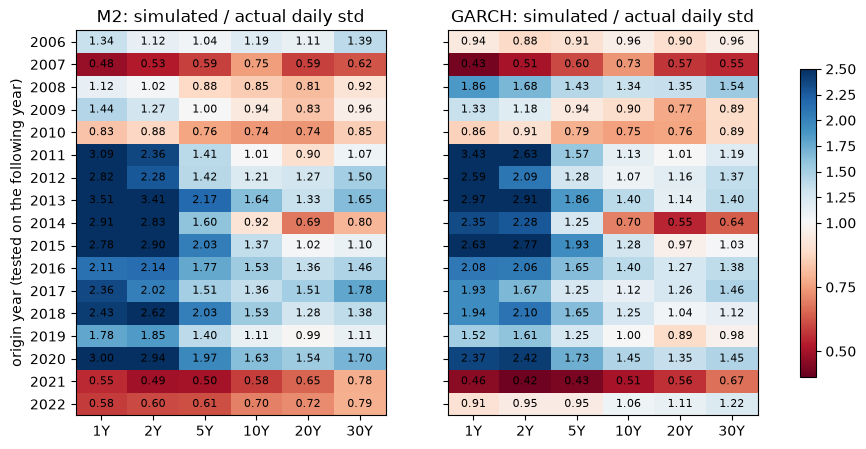

mean |log ratio|  (0 = calibrated): {'M2': 0.446, 'GARCH': 0.397}


In [11]:
ratio = {k: pd.DataFrame(v["sim_std"], index=mats).T / pd.DataFrame(act_std, index=mats).T for k, v in res.items()}
print("GARCH simulated / actual daily std")
print(ratio["GARCH"].round(2))
print("\nM2 simulated / actual daily std")
print(ratio["M2"].round(2))
print("\nGARCH 5-95% coverage by origin")
print(t90["GARCH"].round(2))
print("\nM2 5-95% coverage by origin")
print(t90["M2"].round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, k in zip(axes, ["M2", "GARCH"]):
    r = ratio[k]
    im = ax.imshow(r.values, cmap="RdBu", norm=TwoSlopeNorm(vcenter=1, vmin=0.4, vmax=2.5), aspect="auto")
    ax.set_xticks(range(6)); ax.set_xticklabels(mats)
    ax.set_yticks(range(len(r))); ax.set_yticklabels([o[:4] for o in r.index])
    for a in range(r.shape[0]):
        for b in range(r.shape[1]):
            ax.text(b, a, f"{r.values[a, b]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(f"{k}: simulated / actual daily std")
axes[0].set_ylabel("origin year (tested on the following year)")
fig.colorbar(im, ax=axes, shrink=0.8); plt.show()
print("mean |log ratio|  (0 = calibrated):", {k: round(float(np.abs(np.log(r.values)).mean()), 3) for k, r in ratio.items()})

## Results

**Data.** 6,684 daily observations (2000-08 to 2026-11), no gaps beyond public holidays. Daily changes correlate 0.58 with ECB AAA at 10Y (the ECB curve partly lags by a day), 0.89 over 5 days and 0.96 over 20 days.

**The M4 / M4.5 findings repeat on the longer history.**
- **Variance ratio.** Realised var(250d) / (250 x var(daily)) is 3.5 (1Y), 1.9 (2Y), 1.1 (5Y), 0.9 (10Y), 0.9 (20Y), 0.7 (30Y); both models give 0.9-1.0 throughout. The short-end excess is smaller than on ECB AAA (5.7 and 2.5) but still large, so trending at the short end is not a feature of the ECB series alone.
- **Design B (17 origins, 2006-2022).** Mean |coverage - nominal| for the 5-95% band is 0.185 (M2) and 0.193 (GARCH); for 25-75% it is 0.311 and 0.300. Daily-std calibration improves modestly (mean |log ratio| 0.446 to 0.397). No clear winner between the models.
- **Same regimes fail.** Calm years 2012-2019 are covered at 1.00 at 1Y-5Y (bands too wide, daily std 1.5-3.5 times too high at 1Y-2Y); the 2020-21 origins are far too narrow (1Y coverage 0.43-0.46 and 0.00); and the 2007 origin, tested on 2008, has 1Y coverage 0.00 for both models. GARCH does not anticipate either regime change.
- **Design A (cut 2018).** GARCH test coverage is lower than M2 at every maturity (5-95%: 1Y 0.53 against 0.61, 30Y 0.82 against 0.88), as on ECB AAA.

**Estimation note.** The PC3 fit sits on the stationarity boundary (alpha + beta = 1.000, long-run variance undefined) and PC2 is at 0.999. The constraint alpha + beta <= 1 is binding, so GARCH volatility does not mean-revert for these factors; this is why the table shows an infinite long-run std for PC3.

**Conclusion.** Extending the sample from 22 to 26 years and from 11 to 17 test origins leaves the conclusions unchanged: the horizon miscalibration, the short-end trending and the lack of benefit from GARCH are not artefacts of the short ECB history. The gain in data is modest because the Bundesbank daily series starts in 2000 for the full maturity range.